# RQ2 - Point forecasting with lagged weather

**Member 3 - retrospective weather-aware evaluation.** Three global estimators x five frozen weather ablations x four expanding-window folds (60 experiments). The target is next-day store-family sales. Model parameters remain fixed within each test block; observed sales through day *t-1* may update history features. ERA5 lag availability is a retrospective assumption, not verified operational availability.

This notebook continues the original import/data-loading cells. All predictions, diagnostics and results remain in memory or notebook outputs; no result files are written.

Run with the repository `.venv` kernel (Python 3.11); the recorded package versions below describe the executed environment.

In [12]:
import os
os.environ["PYTHONDONTWRITEBYTECODE"] = "1"
for variable in ("OMP_NUM_THREADS", "MKL_NUM_THREADS", "OPENBLAS_NUM_THREADS", "NUMEXPR_NUM_THREADS"):
    os.environ[variable] = "2"

import sys
sys.dont_write_bytecode = True
import numpy as np
import pandas as pd
import sklearn
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown, HTML
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 16)


In [13]:
from pathlib import Path
import pandas as pd

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "configs/research_protocol.yaml").is_file()), None)
assert ROOT is not None, "Run from the repository or a notebook subdirectory."
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.forecasting.rolling_validation import read_yaml
PROTOCOL = read_yaml(ROOT / "configs/research_protocol.yaml")
ABLATION = read_yaml(ROOT / "configs/ablation_M0_M5.yaml")
FAMILIES = PROTOCOL["scope"]["deep_study_families"]
DATA_PATH = ROOT / "data/processed/model_features.parquet"
# Predicate pushdown avoids loading the other 26 families into RAM.
df = pd.read_parquet(DATA_PATH, filters=[("family", "in", FAMILIES)])
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())
display(df.head())


Shape: (636552, 35)
Columns: ['date', 'store_nbr', 'family', 'sales', 'onpromotion', 'city', 'state', 'store_type', 'cluster', 'weather_grid_id', 'store_active', 'store_zero_day', 'year', 'month', 'day_of_week', 'is_payday', 'is_day_off', 'is_national_holiday', 'is_regional_holiday', 'is_local_holiday', 'is_event', 'is_work_day', 'is_earthquake_period', 'sales_lag1', 'sales_lag7', 'sales_lag14', 'sales_lag28', 'sales_roll7_mean', 'sales_roll28_mean', 'precipitation_sum_lag1', 'temperature_2m_max_lag1', 'relative_humidity_2m_mean_lag1', 'sunshine_hours_lag1', 'excluded_post_reopening', 'score_mask']


,date,store_nbr,family,sales,onpromotion,city,state,store_type,...,sales_roll7_mean,sales_roll28_mean,precipitation_sum_lag1,temperature_2m_max_lag1,relative_humidity_2m_mean_lag1,sunshine_hours_lag1,excluded_post_reopening,score_mask
0,2013-01-01,1,BEVERAGES,0.0,0,Quito,Pichincha,D,...,NaN,NaN,NaN,NaN,NaN,NaN,False,False
1,2013-01-01,1,BREAD/BAKERY,0.0,0,Quito,Pichincha,D,...,NaN,NaN,NaN,NaN,NaN,NaN,False,False
2,2013-01-01,1,CLEANING,0.0,0,Quito,Pichincha,D,...,NaN,NaN,NaN,NaN,NaN,NaN,False,False
3,2013-01-01,1,DAIRY,0.0,0,Quito,Pichincha,D,...,NaN,NaN,NaN,NaN,NaN,NaN,False,False
4,2013-01-01,1,FROZEN FOODS,0.0,0,Quito,Pichincha,D,...,NaN,NaN,NaN,NaN,NaN,NaN,False,False


## Frozen design and data audit

The non-weather feature set is unchanged across M0-M4: calendar indicators, calendar-aligned sales lags (1, 7, 14, 28 days), past-only rolling means (7, 28 days), and store/family/city identifiers. Promotions, transactions, contemporaneous weather and wind are excluded. Median imputation and missingness indicators are learned on each fitting split. Ridge additionally standardizes numeric inputs; Ridge uses one-hot identifiers; Extra Trees uses train-fitted ordinal identifiers (unknown code -1); histogram boosting uses native categorical identifiers (unknown categories mapped to missing). Ordinal codes impose an arbitrary ordering in Extra Trees, an explicit efficiency tradeoff; encoding is fixed across its five ablations.

Validation MAE alone selects parameters with the same candidate budget across ablations within a model. Each selected estimator and its preprocessing are freshly refitted on train + validation, excluding closure targets but retaining reopening cooldown targets. Validation/test scoring follows the shared `score_mask`; missing features never remove scored rows. Missing dates remain missing, including 25 December.

In [14]:
import gc, hashlib, json, platform, time
from importlib.metadata import version
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import ExtraTreesRegressor, HistGradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from threadpoolctl import threadpool_limits
from src.forecasting.feature_spec import FEATURES, m0_numeric
from src.forecasting.point_models import prepare_features
from src.forecasting.rolling_validation import iter_folds, calendar_sales_lag, calendar_rolling_mean
from src.forecasting.evaluation import mase_scales

SEED = int(PROTOCOL["project"]["seed"])
np.random.seed(SEED)
NUMERIC = m0_numeric()
CATEGORICAL = FEATURES["categorical"]
WEATHER = {k: ABLATION["experiments"][k]["weather_features"] for k in ["M0", "M1", "M2", "M3", "M4"]}
assert len(FAMILIES) == 7 and len(set(FAMILIES)) == 7
assert [f["fold_id"] for f in PROTOCOL["rq2"]["validation"]["test_folds"]] == ["F1", "F2", "F3", "F4"]
assert WEATHER == {
    "M0": [], "M1": ["precipitation_sum_lag1"], "M2": ["temperature_2m_max_lag1"],
    "M3": ["precipitation_sum_lag1", "temperature_2m_max_lag1"],
    "M4": FEATURES["weather"],
}
assert ABLATION["evaluation"]["mase_seasonality_days"] == 7
assert not set(NUMERIC + CATEGORICAL) & set(FEATURES["weather"] + FEATURES["conditional"])
# An exported helper would collide with the shared splitter's recomputed helper.
# Preserve the supplied mask: iter_folds checks it against the frozen rules.
df = df.drop(columns=["excluded_post_reopening", "excluded_closure"], errors="ignore")
df = prepare_features(df, ready=True)  # Audits every supplied sales lag and rolling mean.
for c in NUMERIC + FEATURES["weather"]:
    assert pd.api.types.is_numeric_dtype(df[c])
    assert not np.isinf(df[c].to_numpy(dtype=float)).any()
weather_consistency = df.groupby(["city", "date"], observed=True)[FEATURES["weather"]].nunique(dropna=False)
assert weather_consistency.le(1).all().all(), "Weather must be unique per city-date."
del weather_consistency
# Perturb contemporaneous/future labels: all feature sources at the cutoff are unchanged.
cutoff = pd.Timestamp("2017-03-14")
audit_series = df.loc[(df.store_nbr == "44") & (df.family == "BEVERAGES")].copy()
assert not audit_series.empty
changed = audit_series.copy()
changed.loc[changed.date >= cutoff, "sales"] += 1e6
for lag in FEATURES["sales_lags"]:
    assert np.allclose(calendar_sales_lag(audit_series, lag)[audit_series.date <= cutoff],
                       calendar_sales_lag(changed, lag)[changed.date <= cutoff], equal_nan=True)
for days in FEATURES["sales_rolling"]:
    assert np.allclose(calendar_rolling_mean(audit_series, days)[audit_series.date <= cutoff],
                       calendar_rolling_mean(changed, days)[changed.date <= cutoff], equal_nan=True)
# Float32 input bounds dense histogram-boosting matrices; audit happened at source precision.
df[NUMERIC + FEATURES["weather"]] = df[NUMERIC + FEATURES["weather"]].astype("float32")

def sha256_file(path):
    digest = hashlib.sha256()
    with open(path, "rb") as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()

provenance = {
    "python": platform.python_version(), "seed": SEED, "cpu_threads": 2,
    "packages": {p: version(p) for p in ["numpy", "pandas", "scipy", "scikit-learn", "pyarrow", "matplotlib", "seaborn"]},
    "source_sha256": {str(p.relative_to(ROOT)): sha256_file(p) for p in [DATA_PATH,
        ROOT / "configs/research_protocol.yaml", ROOT / "configs/ablation_M0_M5.yaml",
        ROOT / "src/forecasting/feature_spec.py", ROOT / "src/features/lag_features.py",
        ROOT / "src/forecasting/rolling_validation.py", ROOT / "src/forecasting/evaluation.py"]},
}
print(json.dumps(provenance, indent=2))
display(pd.DataFrame({"ablation": list(WEATHER), "weather_features": list(WEATHER.values())}))
display(df[NUMERIC + FEATURES["weather"]].isna().sum().rename("missing_rows").to_frame().T)
print("Sales history audit and city-date weather consistency: PASS.")
print("Raw weather files are unavailable locally; t-1 weather alignment relies on the audited builder contract, not an independent raw-weather reconstruction.")

{
  "python": "3.11.9",
  "seed": 42,
  "cpu_threads": 2,
  "packages": {
    "numpy": "2.4.6",
    "pandas": "2.3.3",
    "scipy": "1.17.1",
    "scikit-learn": "1.9.1",
    "pyarrow": "26.0.1",
    "matplotlib": "3.11.2",
    "seaborn": "0.13.2"
  },
  "source_sha256": {
    "data\\processed\\model_features.parquet": "f6afa64da4830e5b5fe397095333511a96372d5dfb944f2e61b5f77a6b4516a8",
    "configs\\research_protocol.yaml": "0f2a3634e588968022d5d466c64f592fc3627f0306ce9a62b8d4926cbe197f52",
    "configs\\ablation_M0_M5.yaml": "8e6d58bccdb7eba9da74447131f2e1695c4268ab0439ba4e612ccea827fbf48b",
    "src\\forecasting\\feature_spec.py": "24e259491ea48459907bf37607c0ee50543989278a135176aa388cb6bbffce3e",
    "src\\features\\lag_features.py": "76b201d5938565b9f88d1e69ac0a16334e3ffe13f33051eefd24060c123ed583",
    "src\\forecasting\\rolling_validation.py": "1d43d7caa360c45bd5388924287061bc25c46d80f9d5bbbe7ee47b382130f45d",
    "src\\forecasting\\evaluation.py": "e0a5cb4c38d2fa26a135f2fe5a093c

,ablation,weather_features
0,M0,[]
1,M1,[precipitation_sum_lag1]
2,M2,[temperature_2m_max_lag1]
3,M3,"[precipitation_sum_lag1, temperature_2m_max_lag1]"
4,M4,"[precipitation_sum_lag1, temperature_2m_max_la..."


,sales_lag1,sales_lag7,sales_lag14,sales_lag28,sales_roll7_mean,sales_roll28_mean,day_of_week,month,...,is_event,is_work_day,is_payday,is_earthquake_period,precipitation_sum_lag1,temperature_2m_max_lag1,relative_humidity_2m_mean_lag1,sunshine_hours_lag1
missing_rows,1890,4158,6804,12096,378,378,0,0,...,0,0,0,0,378,378,378,378


Sales history audit and city-date weather consistency: PASS.
Raw weather files are unavailable locally; t-1 weather alignment relies on the audited builder contract, not an independent raw-weather reconstruction.


## Training and validation selection

Compact grids are fixed before held-out evaluation: Ridge uses three regularization strengths; Extra Trees uses 48 trees, depth 16 and two leaf sizes; histogram boosting uses 120 iterations and two leaf counts. Extra Trees uses two workers; native numerical libraries are limited to two threads, and experiments run sequentially. Boosting disables internal early stopping to avoid an implicit random validation split. All models fit untransformed sales and predictions are clipped at zero in validation and test alike.

The initial Ridge/M0/F1 experiment is also a deterministic rerun check; its result is reused as the first of the 60 experiments. Four subsequent cells execute one fold at a time, releasing fitted models and large training matrices after each experiment.

Extra Trees uses compact float32 ordinal identifier matrices to control CPU and RAM; Ridge uses sparse one-hot matrices, and histogram boosting uses compact native categorical matrices. Runtime checks motivated this encoding choice before any Extra Trees test evaluation; the final design below is fixed for all folds.

In [15]:
GRIDS = {
    "Ridge": [{"alpha": a} for a in (1.0, 100.0, 10000.0)],
    "ExtraTrees": [{"n_estimators": 48, "max_depth": 16, "min_samples_leaf": leaf,
                    "max_features": 0.75} for leaf in (10, 30)],
    "HistGradientBoosting": [{"max_iter": 120, "learning_rate": 0.08,
        "max_leaf_nodes": leaves, "min_samples_leaf": 30, "l2_regularization": 1.0}
        for leaves in (15, 31)],
}
MODELS = list(GRIDS)
print(json.dumps(GRIDS, indent=2))

# A generator retains only the current fold's frames, not four copies of the history.
fold_iterator = iter(iter_folds(df, PROTOCOL, ABLATION, FAMILIES))
fold = next(fold_iterator)
prediction_parts, tuning_rows, experiment_rows, split_rows, exclusion_parts = [], [], [], [], []
scale_parts, scored_keys, reproducibility_rows = [], {}, []


def preprocess(model_name, numeric):
    steps = [("imputer", SimpleImputer(strategy="median", add_indicator=True, keep_empty_features=True))]
    if model_name == "Ridge":
        steps.append(("scaler", StandardScaler()))
    if model_name == "Ridge":
        encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=True, dtype=np.float32)
    else:
        # Tree thresholds can split identifier codes; HGB treats them as native categories.
        unknown = np.nan if model_name == "HistGradientBoosting" else -1
        encoder = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=unknown,
                                 encoded_missing_value=unknown, dtype=np.float32)
    return ColumnTransformer([
        ("numeric", Pipeline(steps), numeric),
        ("categorical", encoder, CATEGORICAL),
    ], sparse_threshold=1.0 if model_name == "Ridge" else 0.0)


def estimator(model_name, parameters, prep):
    if model_name == "Ridge":
        return Ridge(solver="lsqr", tol=1e-6, max_iter=5000, **parameters)
    if model_name == "ExtraTrees":
        return ExtraTreesRegressor(random_state=SEED, n_jobs=2, **parameters)
    cat = prep.output_indices_["categorical"]
    return HistGradientBoostingRegressor(random_state=SEED, early_stopping=False,
        categorical_features=list(range(cat.start, cat.stop)), **parameters)


def audit_imputer(prep, rows, numeric):
    expected = rows[numeric].median().fillna(0).to_numpy()
    actual = prep.named_transformers_["numeric"].named_steps["imputer"].statistics_
    assert np.allclose(actual, expected, rtol=1e-5, atol=1e-6), "Imputer was not fitted on eligible fitting rows."


def nonnegative_predict(fitted, values):
    prediction = np.maximum(fitted.predict(values), 0.0)
    assert np.isfinite(prediction).all()
    return prediction


def run_experiment(fold, model_name, config, repeat_check=False):
    start = time.perf_counter()
    numeric = NUMERIC + WEATHER[config]
    features = numeric + CATEGORICAL
    assert len(features) == len(set(features))
    validation = fold.validation.loc[fold.validation.score_mask]
    test = fold.test.loc[fold.test.score_mask]
    prep = preprocess(model_name, numeric)
    with threadpool_limits(limits=2):
        x_train = prep.fit_transform(fold.train[features])
        audit_imputer(prep, fold.train, numeric)
        x_validation = prep.transform(validation[features])
        frozen_statistics = prep.named_transformers_["numeric"].named_steps["imputer"].statistics_.copy()
        candidate_rows = []
        for candidate_number, parameters in enumerate(GRIDS[model_name], start=1):
            candidate_start = time.perf_counter()
            print(f"  {fold.fold_id}/{model_name}/{config}: fitting candidate {candidate_number}/{len(GRIDS[model_name])}", flush=True)
            fitted = estimator(model_name, parameters, prep)
            fitted.fit(x_train, fold.train.sales.to_numpy())
            prediction = nonnegative_predict(fitted, x_validation)
            score = float(np.mean(np.abs(validation.sales.to_numpy() - prediction)))
            candidate_rows.append({"parameters": json.dumps(parameters, sort_keys=True), "validation_MAE": score})
            print(f"    validation MAE={score:.3f}; {time.perf_counter()-candidate_start:.1f}s", flush=True)
            del fitted
        assert np.array_equal(frozen_statistics,
            prep.named_transformers_["numeric"].named_steps["imputer"].statistics_)
        best_index = int(np.argmin([r["validation_MAE"] for r in candidate_rows]))
        best = GRIDS[model_name][best_index]
        for i, row in enumerate(candidate_rows):
            tuning_rows.append({"fold": fold.fold_id, "model": model_name, "ablation": config,
                                **row, "selected": i == best_index})
        del x_train, x_validation, prep
        gc.collect()
        refit = fold.refit_rows()
        assert refit.date.max() < test.date.min()
        assert refit.store_zero_day.eq(0).all()
        prep = preprocess(model_name, numeric)
        x_refit = prep.fit_transform(refit[features])
        audit_imputer(prep, refit, numeric)
        print(f"  {fold.fold_id}/{model_name}/{config}: refitting selected parameters", flush=True)
        fitted = estimator(model_name, best, prep)
        fitted.fit(x_refit, refit.sales.to_numpy())
        x_test = prep.transform(test[features])
        prediction = nonnegative_predict(fitted, x_test)
        if repeat_check:
            # Fresh preprocessing and estimator, same seed/data/selected parameters.
            repeat_prep = preprocess(model_name, numeric)
            repeat_x = repeat_prep.fit_transform(refit[features])
            repeated = estimator(model_name, best, repeat_prep)
            repeated.fit(repeat_x, refit.sales.to_numpy())
            repeated_prediction = nonnegative_predict(repeated, repeat_prep.transform(test[features]))
            difference = float(np.max(np.abs(prediction - repeated_prediction)))
            assert np.allclose(prediction, repeated_prediction, rtol=1e-10, atol=1e-8)
            reproducibility_rows.append({"fold": fold.fold_id, "model": model_name,
                "ablation": config, "max_absolute_difference": difference, "passed": True})
            del repeat_prep, repeat_x, repeated
    output = test[["date", "store_nbr", "family", "city"]].copy()
    output["fold"], output["model"], output["ablation"] = fold.fold_id, model_name, config
    output["y_true"], output["y_pred"] = test.sales.to_numpy(), prediction
    keys = pd.MultiIndex.from_frame(output[["date", "store_nbr", "family"]])
    assert keys.equals(scored_keys[fold.fold_id]), "Scored test keys changed across experiments."
    assert len(prediction) == int(fold.test.score_mask.sum())
    prediction_parts.append(output)
    row = {"fold": fold.fold_id, "model": model_name, "ablation": config,
           "n_train": len(fold.train), "n_refit": len(refit), "n_scored": len(test),
           "best_parameters": json.dumps(best, sort_keys=True),
           "validation_MAE": candidate_rows[best_index]["validation_MAE"],
           "test_MAE": float(np.mean(np.abs(output.y_true - output.y_pred))),
           "seconds": time.perf_counter() - start}
    experiment_rows.append(row)
    print(f"[{len(experiment_rows):02d}/60] {fold.fold_id} {model_name:22s} {config}: "
          f"MAE={row['test_MAE']:.3f}; validation={row['validation_MAE']:.3f}; {row['seconds']:.1f}s", flush=True)
    del fitted, prep, refit, x_refit, x_test
    gc.collect()
    return row


def register_fold(fold):
    assert fold.train.date.max() < fold.validation.date.min()
    assert fold.validation.date.max() < fold.test.date.min()
    assert fold.train.store_zero_day.eq(0).all()
    scored_keys[fold.fold_id] = pd.MultiIndex.from_frame(
        fold.test.loc[fold.test.score_mask, ["date", "store_nbr", "family"]])
    scale = mase_scales(fold.train, df)
    scale["fold"] = fold.fold_id
    scale_parts.append(scale)
    exclusion_parts.append(fold.counts)
    for split, rows in [("train", fold.train), ("validation", fold.validation), ("test", fold.test)]:
        split_rows.append({"fold": fold.fold_id, "split": split, "rows": len(rows),
            "start": rows.date.min(), "end": rows.date.max(),
            "training_closure_rows_removed": fold.training_rows_excluded if split == "train" else 0})
    print(f"{fold.fold_id}: train={len(fold.train):,}; scored validation={fold.validation.score_mask.sum():,}; "
          f"scored test={fold.test.score_mask.sum():,}", flush=True)


def complete_fold(fold):
    done = {(r["fold"], r["model"], r["ablation"]) for r in experiment_rows}
    for model_name in MODELS:
        for config in WEATHER:
            if (fold.fold_id, model_name, config) not in done:
                run_experiment(fold, model_name, config)
    display(pd.DataFrame(experiment_rows).query("fold == @fold.fold_id").round(3))

register_fold(fold)
smoke_result = run_experiment(fold, "Ridge", "M0", repeat_check=True)
display(pd.DataFrame(reproducibility_rows))

{
  "Ridge": [
    {
      "alpha": 1.0
    },
    {
      "alpha": 100.0
    },
    {
      "alpha": 10000.0
    }
  ],
  "ExtraTrees": [
    {
      "n_estimators": 48,
      "max_depth": 16,
      "min_samples_leaf": 10,
      "max_features": 0.75
    },
    {
      "n_estimators": 48,
      "max_depth": 16,
      "min_samples_leaf": 30,
      "max_features": 0.75
    }
  ],
  "HistGradientBoosting": [
    {
      "max_iter": 120,
      "learning_rate": 0.08,
      "max_leaf_nodes": 15,
      "min_samples_leaf": 30,
      "l2_regularization": 1.0
    },
    {
      "max_iter": 120,
      "learning_rate": 0.08,
      "max_leaf_nodes": 31,
      "min_samples_leaf": 30,
      "l2_regularization": 1.0
    }
  ]
}
F1: train=446,544; scored validation=10,199; scored test=9,996
  F1/Ridge/M0: fitting candidate 1/3
    validation MAE=170.792; 2.3s
  F1/Ridge/M0: fitting candidate 2/3
    validation MAE=170.803; 2.0s
  F1/Ridge/M0: fitting candidate 3/3
    validation MAE=173.450; 0.9s
  F1/

,fold,model,ablation,max_absolute_difference,passed
0,F1,Ridge,M0,0.0,True


### F1 - 15 experiments

In [16]:
complete_fold(fold)

  F1/Ridge/M1: fitting candidate 1/3
    validation MAE=170.674; 2.7s
  F1/Ridge/M1: fitting candidate 2/3
    validation MAE=170.678; 2.5s
  F1/Ridge/M1: fitting candidate 3/3
    validation MAE=173.240; 1.2s
  F1/Ridge/M1: refitting selected parameters
[02/60] F1 Ridge                  M1: MAE=217.929; validation=170.674; 12.9s
  F1/Ridge/M2: fitting candidate 1/3
    validation MAE=171.025; 2.6s
  F1/Ridge/M2: fitting candidate 2/3
    validation MAE=171.025; 2.4s
  F1/Ridge/M2: fitting candidate 3/3
    validation MAE=173.486; 1.1s
  F1/Ridge/M2: refitting selected parameters
[03/60] F1 Ridge                  M2: MAE=218.069; validation=171.025; 12.3s
  F1/Ridge/M3: fitting candidate 1/3
    validation MAE=170.881; 2.8s
  F1/Ridge/M3: fitting candidate 2/3
    validation MAE=170.877; 2.5s
  F1/Ridge/M3: fitting candidate 3/3
    validation MAE=173.274; 1.0s
  F1/Ridge/M3: refitting selected parameters
[04/60] F1 Ridge                  M3: MAE=218.159; validation=170.877; 13.0s
  F1

KeyboardInterrupt: 

### F2 - 15 experiments

In [ ]:
del fold
gc.collect()
fold = next(fold_iterator)
register_fold(fold)
complete_fold(fold)

F2: train=473,522; scored validation=9,989; scored test=10,108


  F2/Ridge/M0: fitting candidate 1/3


    validation MAE=230.719; 2.3s


  F2/Ridge/M0: fitting candidate 2/3


    validation MAE=230.945; 2.0s


  F2/Ridge/M0: fitting candidate 3/3


... (92 outputs left out)

    validation MAE=188.704; 5.0s


  F2/HistGradientBoosting/M4: refitting selected parameters


[30/60] F2 HistGradientBoosting   M4: MAE=238.891; validation=188.704; 17.1s


,fold,model,ablation,n_train,n_refit,n_scored,best_parameters,validation_MAE,test_MAE,seconds
15,F2,Ridge,M0,473522,483644,10108,"{""alpha"": 1.0}",230.719,268.937,11.271
16,F2,Ridge,M1,473522,483644,10108,"{""alpha"": 1.0}",230.658,269.012,12.647
17,F2,Ridge,M2,473522,483644,10108,"{""alpha"": 1.0}",230.447,269.100,13.370
18,F2,Ridge,M3,473522,483644,10108,"{""alpha"": 1.0}",230.339,269.212,13.022
19,F2,Ridge,M4,473522,483644,10108,"{""alpha"": 1.0}",230.662,270.316,16.190
20,F2,ExtraTrees,M0,473522,483644,10108,"{""max_depth"": 16, ""max_features"": 0.75, ""min_s...",192.009,234.296,132.591
21,F2,ExtraTrees,M1,473522,483644,10108,"{""max_depth"": 16, ""max_features"": 0.75, ""min_s...",191.817,232.158,142.355
22,F2,ExtraTrees,M2,473522,483644,10108,"{""max_depth"": 16, ""max_features"": 0.75, ""min_s...",191.923,234.746,140.044
23,F2,ExtraTrees,M3,473522,483644,10108,"{""max_depth"": 16, ""max_features"": 0.75, ""min_s...",193.065,234.230,180.645
24,F2,ExtraTrees,M4,473522,483644,10108,"{""max_depth"": 16, ""max_features"": 0.75, ""min_s...",192.734,232.297,159.560


### F3 - 15 experiments

In [ ]:
del fold
gc.collect()
fold = next(fold_iterator)
register_fold(fold)
complete_fold(fold)

F3: train=511,700; scored validation=10,388; scored test=10,388


  F3/Ridge/M0: fitting candidate 1/3


    validation MAE=243.267; 2.0s


  F3/Ridge/M0: fitting candidate 2/3


    validation MAE=243.242; 2.0s


  F3/Ridge/M0: fitting candidate 3/3


... (92 outputs left out)

    validation MAE=214.825; 5.2s


  F3/HistGradientBoosting/M4: refitting selected parameters


[45/60] F3 HistGradientBoosting   M4: MAE=199.148; validation=214.825; 18.0s


,fold,model,ablation,n_train,n_refit,n_scored,best_parameters,validation_MAE,test_MAE,seconds
30,F3,Ridge,M0,511700,522088,10388,"{""alpha"": 100.0}",243.242,257.282,11.143
31,F3,Ridge,M1,511700,522088,10388,"{""alpha"": 100.0}",243.037,257.774,12.667
32,F3,Ridge,M2,511700,522088,10388,"{""alpha"": 100.0}",243.163,257.171,13.674
33,F3,Ridge,M3,511700,522088,10388,"{""alpha"": 100.0}",242.916,257.709,13.945
34,F3,Ridge,M4,511700,522088,10388,"{""alpha"": 100.0}",242.436,256.779,15.823
35,F3,ExtraTrees,M0,511700,522088,10388,"{""max_depth"": 16, ""max_features"": 0.75, ""min_s...",221.679,208.646,132.433
36,F3,ExtraTrees,M1,511700,522088,10388,"{""max_depth"": 16, ""max_features"": 0.75, ""min_s...",220.701,199.395,192.242
37,F3,ExtraTrees,M2,511700,522088,10388,"{""max_depth"": 16, ""max_features"": 0.75, ""min_s...",221.322,200.183,197.539
38,F3,ExtraTrees,M3,511700,522088,10388,"{""max_depth"": 16, ""max_features"": 0.75, ""min_s...",221.666,208.221,236.277
39,F3,ExtraTrees,M4,511700,522088,10388,"{""max_depth"": 16, ""max_features"": 0.75, ""min_s...",221.698,199.748,238.577


### F4 - 15 experiments

In [ ]:
del fold
gc.collect()
fold = next(fold_iterator)
register_fold(fold)
complete_fold(fold)

F4: train=564,074; scored validation=10,584; scored test=10,584


  F4/Ridge/M0: fitting candidate 1/3


    validation MAE=221.818; 2.1s


  F4/Ridge/M0: fitting candidate 2/3


    validation MAE=221.446; 2.1s


  F4/Ridge/M0: fitting candidate 3/3


... (92 outputs left out)

    validation MAE=186.155; 5.8s


  F4/HistGradientBoosting/M4: refitting selected parameters


[60/60] F4 HistGradientBoosting   M4: MAE=215.321; validation=186.155; 19.7s


,fold,model,ablation,n_train,n_refit,n_scored,best_parameters,validation_MAE,test_MAE,seconds
45,F4,Ridge,M0,564074,574658,10584,"{""alpha"": 100.0}",221.446,242.699,11.879
46,F4,Ridge,M1,564074,574658,10584,"{""alpha"": 100.0}",221.331,242.499,13.511
47,F4,Ridge,M2,564074,574658,10584,"{""alpha"": 100.0}",221.455,242.738,13.980
48,F4,Ridge,M3,564074,574658,10584,"{""alpha"": 100.0}",221.341,242.536,15.329
49,F4,Ridge,M4,564074,574658,10584,"{""alpha"": 100.0}",221.109,242.201,17.154
50,F4,ExtraTrees,M0,564074,574658,10584,"{""max_depth"": 16, ""max_features"": 0.75, ""min_s...",186.088,215.688,148.843
51,F4,ExtraTrees,M1,564074,574658,10584,"{""max_depth"": 16, ""max_features"": 0.75, ""min_s...",185.914,215.431,171.751
52,F4,ExtraTrees,M2,564074,574658,10584,"{""max_depth"": 16, ""max_features"": 0.75, ""min_s...",185.936,215.096,177.638
53,F4,ExtraTrees,M3,564074,574658,10584,"{""max_depth"": 16, ""max_features"": 0.75, ""min_s...",185.929,215.473,191.335
54,F4,ExtraTrees,M4,564074,574658,10584,"{""max_depth"": 16, ""max_features"": 0.75, ""min_s...",186.676,214.260,206.014


## Metrics and paired weather uplift

MAE is the primary metric in sales units. WAPE is reported as a percentage of absolute observed sales. MASE averages row-wise absolute errors divided by each store-family series mean absolute 7-calendar-day difference from **training only**; invalid scales are excluded from MASE alone and their coverage is reported. Pooled metrics weight scored rows, rather than averaging city/family metrics. Fold mean and standard deviation are also shown separately.

Weather uplift is `100 * (MAE_M0 - MAE_Mk) / MAE_M0` within the same model and identical test keys; positive values indicate improvement. Exploratory paired 95% intervals resample four non-overlapping 7-day blocks within each of the four folds (1,000 draws), preserving within-day store/family dependence. Intervals are descriptive with only four origins and are not adjusted for multiple comparisons. A held-out ranking describes these experiments; it does not independently validate a deployed model choice.

Uplift compares complete validation-selected pipelines: the chosen hyperparameters may differ across ablations. It therefore measures the effect of adding weather within this tuning procedure, rather than an isolated causal weather effect.

In [ ]:
del fold
fold_iterator.close()
gc.collect()
experiments = pd.DataFrame(experiment_rows)
tuning = pd.DataFrame(tuning_rows)
assert len(experiments) == 60
assert not experiments.duplicated(["fold", "model", "ablation"]).any()
assert experiments.groupby(["model", "ablation"]).fold.nunique().eq(4).all()
assert tuning.groupby(["fold", "model", "ablation"]).selected.sum().eq(1).all()
predictions = pd.concat(prediction_parts, ignore_index=True)
scales = pd.concat(scale_parts, ignore_index=True)
assert not scales.duplicated(["fold", "store_nbr", "family"]).any()
predictions = predictions.merge(scales, on=["fold", "store_nbr", "family"], how="left", validate="many_to_one")
assert not predictions.duplicated(["fold", "model", "ablation", "date", "store_nbr", "family"]).any()
assert np.isfinite(predictions[["y_true", "y_pred"]]).all().all()
assert predictions.y_pred.ge(0).all()
predictions["abs_error"] = (predictions.y_true - predictions.y_pred).abs()
predictions["abs_actual"] = predictions.y_true.abs()
valid_scale = predictions.mase_scale.gt(0) & np.isfinite(predictions.mase_scale)
predictions["scaled_error"] = np.where(valid_scale, predictions.abs_error / predictions.mase_scale, np.nan)
assert predictions.groupby(["fold", "date", "store_nbr", "family"], observed=True).size().eq(15).all()


def metric_table(grouping):
    table = predictions.groupby(grouping, observed=True).agg(
        n_scored=("abs_error", "size"), MAE=("abs_error", "mean"),
        error_sum=("abs_error", "sum"), actual_sum=("abs_actual", "sum"),
        MASE=("scaled_error", "mean"), mase_valid_rows=("scaled_error", "count")).reset_index()
    table["WAPE_pct"] = 100 * table.error_sum.div(table.actual_sum.where(table.actual_sum.gt(0)))
    table["MASE_coverage_pct"] = 100 * table.mase_valid_rows / table.n_scored
    return table.drop(columns=["error_sum", "actual_sum"])

summary = metric_table(["model", "ablation"])
by_fold = metric_table(["model", "ablation", "fold"])
by_family = metric_table(["model", "ablation", "family"])
by_city = metric_table(["model", "ablation", "city"])
by_family_city_fold = metric_table(["model", "ablation", "fold", "family", "city"])
by_store = metric_table(["model", "ablation", "fold", "store_nbr"])
fold_variability = by_fold.groupby(["model", "ablation"]).MAE.agg(
    fold_mean_MAE="mean", fold_sd_MAE="std", fold_min_MAE="min", fold_max_MAE="max").reset_index()
base = by_fold.query("ablation == 'M0'")[["model", "fold", "MAE"]].rename(columns={"MAE": "M0_MAE"})
uplift_by_fold = by_fold.merge(base, on=["model", "fold"], validate="many_to_one")
uplift_by_fold["MAE_reduction"] = uplift_by_fold.M0_MAE - uplift_by_fold.MAE
uplift_by_fold["uplift_pct"] = 100 * uplift_by_fold.MAE_reduction / uplift_by_fold.M0_MAE
base_summary = summary.query("ablation == 'M0'")[["model", "MAE"]].rename(columns={"MAE": "M0_MAE"})
uplift = summary.merge(base_summary, on="model", validate="many_to_one").query("ablation != 'M0'").copy()
uplift["MAE_reduction"] = uplift.M0_MAE - uplift.MAE
uplift["uplift_pct"] = 100 * uplift.MAE_reduction / uplift.M0_MAE
stability = uplift_by_fold.query("ablation != 'M0'").groupby(["model", "ablation"]).agg(
    improved_folds=("uplift_pct", lambda s: int(s.gt(0).sum())),
    min_fold_uplift_pct=("uplift_pct", "min"), max_fold_uplift_pct=("uplift_pct", "max")).reset_index()
uplift = uplift.merge(stability, on=["model", "ablation"], validate="one_to_one")

# Resample paired weekly test blocks within each fold, using the same weights for every comparison.
daily = predictions.groupby(["model", "ablation", "fold", "date"], observed=True).agg(
    error_sum=("abs_error", "sum"), n=("abs_error", "size")).reset_index()
test_starts = {f["fold_id"]: pd.Timestamp(f["test"][0]) for f in PROTOCOL["rq2"]["validation"]["test_folds"]}
daily["block"] = [(date - test_starts[f]).days // 7 for f, date in zip(daily.fold, daily.date)]
blocks = daily.groupby(["model", "ablation", "fold", "block"], observed=True)[["error_sum", "n"]].sum()
rng = np.random.default_rng(SEED)
draws = rng.integers(0, 4, size=(1000, 4, 4))
ci_rows = []
for model_name in MODELS:
    base_blocks = blocks.loc[(model_name, "M0")].sort_index()
    base_errors, counts = base_blocks.error_sum.to_numpy().reshape(4, 4), base_blocks.n.to_numpy().reshape(4, 4)
    base_boot = sum(base_errors[i, draws[:, i, :]].sum(axis=1) for i in range(4))
    for config in list(WEATHER)[1:]:
        comparison = blocks.loc[(model_name, config)].sort_index()
        assert np.array_equal(comparison.n, base_blocks.n)
        errors = comparison.error_sum.to_numpy().reshape(4, 4)
        weather_boot = sum(errors[i, draws[:, i, :]].sum(axis=1) for i in range(4))
        interval = np.quantile(100 * (base_boot - weather_boot) / base_boot, [0.025, 0.975])
        ci_rows.append({"model": model_name, "ablation": config,
                        "uplift_CI_low_pct": interval[0], "uplift_CI_high_pct": interval[1]})
uplift = uplift.merge(pd.DataFrame(ci_rows), on=["model", "ablation"], validate="one_to_one")


def scroll_table(table, caption, height=330):
    display(Markdown(f"**{caption}** ({len(table):,} rows)"))
    display(HTML(f'<div style="max-height:{height}px;overflow:auto">' +
        table.to_html(index=False, float_format=lambda x: f"{x:,.3f}", escape=True) + '</div>'))

display(Markdown("**Pooled held-out metrics - all four folds**"))
display(summary[["model", "ablation", "n_scored", "MAE", "WAPE_pct", "MASE", "MASE_coverage_pct"]].round(4))
display(uplift[["model", "ablation", "MAE_reduction", "uplift_pct", "improved_folds",
               "min_fold_uplift_pct", "max_fold_uplift_pct", "uplift_CI_low_pct", "uplift_CI_high_pct"]].round(3))
scroll_table(by_fold, "Metrics by model / ablation / fold")
scroll_table(fold_variability, "MAE variability across origins")
scroll_table(by_family, "Metrics by model / ablation / family")
scroll_table(by_city, "Metrics by model / ablation / city")
scroll_table(by_family_city_fold, "Joint breakdown: model / ablation / fold / family / city")
scroll_table(by_store.query("store_nbr == '52'"), "Store 52 - F4 only, limited post-opening history")
scroll_table(pd.concat(exclusion_parts, ignore_index=True), "Scoring exclusions (selected seven families)")
scroll_table(pd.DataFrame(split_rows), "Temporal split audit")
scroll_table(experiments, "Selected validation parameters and experiment timings")
scroll_table(tuning, "Complete validation search log")
# Drop redundant lists while retaining row-level predictions and all result tables in the kernel.
prediction_parts.clear()
gc.collect()

**Pooled held-out metrics - all four folds**

,model,ablation,n_scored,MAE,WAPE_pct,MASE,MASE_coverage_pct
0,ExtraTrees,M0,41076,208.2728,12.7590,0.7786,100.0
1,ExtraTrees,M1,41076,205.4769,12.5878,0.7752,100.0
2,ExtraTrees,M2,41076,205.9882,12.6191,0.7756,100.0
3,ExtraTrees,M3,41076,208.0392,12.7447,0.7779,100.0
4,ExtraTrees,M4,41076,205.3200,12.5781,0.7739,100.0
5,HistGradientBoosting,M0,41076,205.5029,12.5893,0.7914,100.0
6,HistGradientBoosting,M1,41076,205.7033,12.6016,0.7933,100.0
7,HistGradientBoosting,M2,41076,205.2249,12.5723,0.7935,100.0
8,HistGradientBoosting,M3,41076,205.4679,12.5872,0.7937,100.0
9,HistGradientBoosting,M4,41076,205.1596,12.5683,0.7927,100.0


,model,ablation,MAE_reduction,uplift_pct,improved_folds,min_fold_uplift_pct,max_fold_uplift_pct,uplift_CI_low_pct,uplift_CI_high_pct
0,ExtraTrees,M1,2.796,1.342,3,-0.322,4.434,0.808,1.926
1,ExtraTrees,M2,2.285,1.097,3,-0.192,4.056,0.618,1.680
2,ExtraTrees,M3,0.234,0.112,4,0.028,0.204,-0.214,0.448
3,ExtraTrees,M4,2.953,1.418,3,-0.373,4.265,0.985,1.878
4,HistGradientBoosting,M1,-0.200,-0.098,2,-0.597,0.486,-0.943,0.840
5,HistGradientBoosting,M2,0.278,0.135,2,-0.540,1.051,-0.240,0.567
6,HistGradientBoosting,M3,0.035,0.017,2,-0.668,0.965,-0.693,0.759
7,HistGradientBoosting,M4,0.343,0.167,2,-1.141,1.145,-0.749,1.203
8,Ridge,M1,-0.105,-0.043,1,-0.191,0.083,-0.151,0.056
9,Ridge,M2,-0.070,-0.028,1,-0.091,0.043,-0.067,0.004


**Metrics by model / ablation / fold** (60 rows)

model,ablation,fold,n_scored,MAE,MASE,mase_valid_rows,WAPE_pct,MASE_coverage_pct
ExtraTrees,M0,F1,9996,173.719,0.683,9996,11.442,100.000
ExtraTrees,M0,F2,10108,234.296,0.884,10108,13.746,100.000
ExtraTrees,M0,F3,10388,208.646,0.762,10388,12.248,100.000
ExtraTrees,M0,F4,10584,215.688,0.784,10584,13.469,100.000
ExtraTrees,M1,F1,9996,174.277,0.681,9996,11.479,100.000
ExtraTrees,M1,F2,10108,232.158,0.880,10108,13.620,100.000
ExtraTrees,M1,F3,10388,199.395,0.752,10388,11.705,100.000
ExtraTrees,M1,F4,10584,215.431,0.787,10584,13.453,100.000
ExtraTrees,M2,F1,9996,173.298,0.681,9996,11.414,100.000
ExtraTrees,M2,F2,10108,234.746,0.884,10108,13.772,100.000


**MAE variability across origins** (15 rows)

... (14 outputs left out)

fold,model,ablation,n_train,n_refit,n_scored,best_parameters,validation_MAE,test_MAE,seconds
F1,Ridge,M0,446544,456743,9996,"{""alpha"": 1.0}",170.792,217.871,13.239
F1,Ridge,M1,446544,456743,9996,"{""alpha"": 1.0}",170.674,217.929,11.828
F1,Ridge,M2,446544,456743,9996,"{""alpha"": 100.0}",171.025,218.069,11.526
F1,Ridge,M3,446544,456743,9996,"{""alpha"": 100.0}",170.877,218.159,11.929
F1,Ridge,M4,446544,456743,9996,"{""alpha"": 1.0}",170.327,217.948,13.956
F1,ExtraTrees,M0,446544,456743,9996,"{""max_depth"": 16, ""max_features"": 0.75, ""min_samples_leaf"": 10, ""n_estimators"": 48}",141.944,173.719,108.312
F1,ExtraTrees,M1,446544,456743,9996,"{""max_depth"": 16, ""max_features"": 0.75, ""min_samples_leaf"": 10, ""n_estimators"": 48}",141.679,174.277,125.885
F1,ExtraTrees,M2,446544,456743,9996,"{""max_depth"": 16, ""max_features"": 0.75, ""min_samples_leaf"": 10, ""n_estimators"": 48}",141.775,173.298,129.917
F1,ExtraTrees,M3,446544,456743,9996,"{""max_depth"": 16, ""max_features"": 0.75, ""min_samples_leaf"": 10, ""n_estimators"": 48}",142.180,173.496,134.383
F1,ExtraTrees,M4,446544,456743,9996,"{""max_depth"": 16, ""max_features"": 0.75, ""min_samples_leaf"": 10, ""n_estimators"": 48}",141.313,174.366,173.839


**Complete validation search log** (140 rows)

fold,model,ablation,parameters,validation_MAE,selected
F1,Ridge,M0,"{""alpha"": 1.0}",170.792,True
F1,Ridge,M0,"{""alpha"": 100.0}",170.803,False
F1,Ridge,M0,"{""alpha"": 10000.0}",173.450,False
F1,Ridge,M1,"{""alpha"": 1.0}",170.674,True
F1,Ridge,M1,"{""alpha"": 100.0}",170.678,False
F1,Ridge,M1,"{""alpha"": 10000.0}",173.240,False
F1,Ridge,M2,"{""alpha"": 1.0}",171.025,False
F1,Ridge,M2,"{""alpha"": 100.0}",171.025,True
F1,Ridge,M2,"{""alpha"": 10000.0}",173.486,False
F1,Ridge,M3,"{""alpha"": 1.0}",170.881,False


3

## Visual comparison

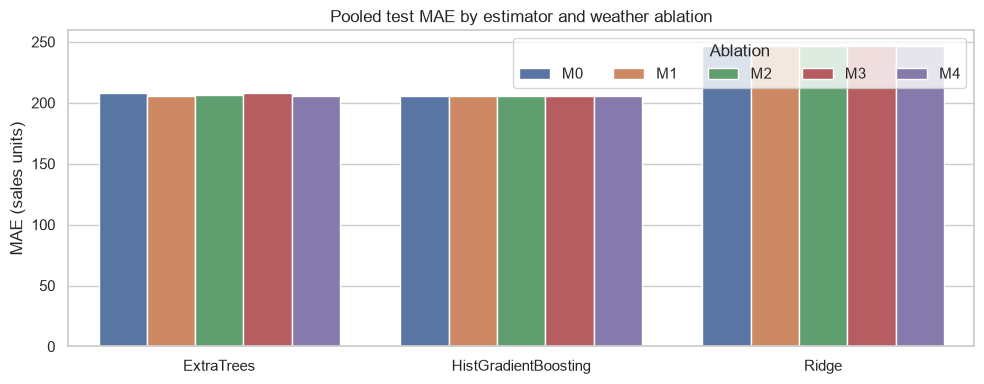

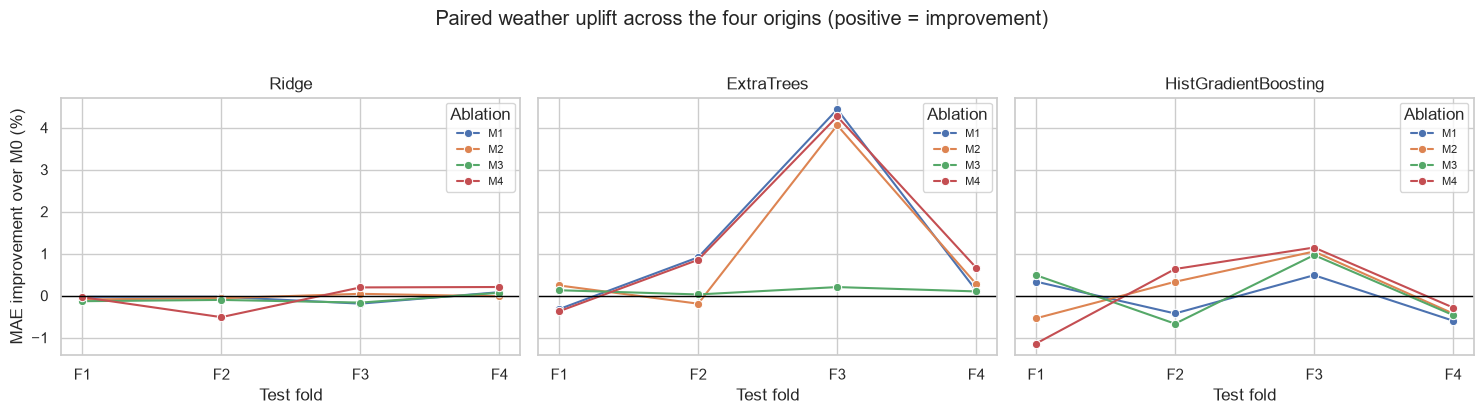

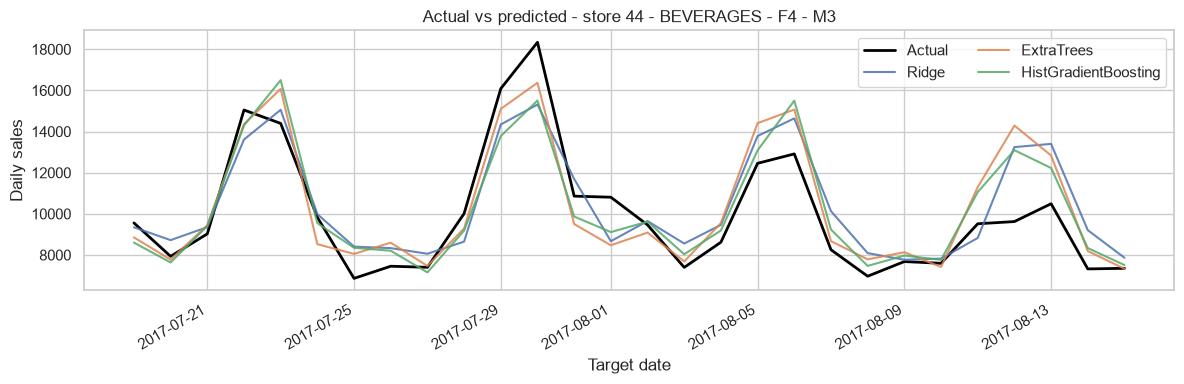

In [ ]:
fig, ax = plt.subplots(figsize=(10, 4))
sns.barplot(data=summary, x="model", y="MAE", hue="ablation", hue_order=list(WEATHER), ax=ax)
ax.set(title="Pooled test MAE by estimator and weather ablation", xlabel="", ylabel="MAE (sales units)")
ax.legend(title="Ablation", ncol=5, loc="upper right")
fig.tight_layout()
plt.show()
plt.close(fig)

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, model_name in zip(axes, MODELS):
    sns.lineplot(data=uplift_by_fold.query("model == @model_name and ablation != 'M0'"),
                 x="fold", y="uplift_pct", hue="ablation", marker="o", ax=ax)
    ax.axhline(0, color="black", lw=1)
    ax.set(title=model_name, xlabel="Test fold", ylabel="MAE improvement over M0 (%)")
    ax.legend(title="Ablation", fontsize=8)
fig.suptitle("Paired weather uplift across the four origins (positive = improvement)", y=1.03)
fig.tight_layout()
plt.show()
plt.close(fig)

# Fixed representative series, chosen before any test results: store 44 / BEVERAGES / F4 / M3.
representative = predictions.query("store_nbr == '44' and family == 'BEVERAGES' and fold == 'F4' and ablation == 'M3'")
assert len(representative) == 28 * len(MODELS)
fig, ax = plt.subplots(figsize=(12, 4))
actual = representative.drop_duplicates("date").sort_values("date")
ax.plot(actual.date, actual.y_true, color="black", linewidth=2, label="Actual")
for model_name in MODELS:
    part = representative.query("model == @model_name").sort_values("date")
    ax.plot(part.date, part.y_pred, label=model_name, alpha=0.85)
ax.set(title="Actual vs predicted - store 44 - BEVERAGES - F4 - M3",
       xlabel="Target date", ylabel="Daily sales")
ax.legend(ncol=2)
fig.autofmt_xdate()
fig.tight_layout()
plt.show()
plt.close(fig)

## Findings and final checks

The lowest pooled MAE belongs to HistGradientBoosting/M4 (205.160), narrowly ahead of Extra Trees/M4 (205.320). However, its weather uplift is only 0.167%, improves two of four folds, and has a block interval spanning zero. Extra Trees/M4 shows the largest pooled weather uplift (1.418%; descriptive 95% interval 0.985% to 1.878%), improving three folds, with most of its gain concentrated in F3. Extra Trees/M3 improves all four folds, but its 0.112% pooled gain is small and its interval includes zero. Ridge shows no pooled MAE improvement from weather.

Extra Trees/M4 has the lowest pooled MASE (0.774), whereas HistGradientBoosting/M4 ranks first on the prespecified primary metric, MAE. These differences support reporting all three metrics and origin-level results rather than declaring a uniform weather benefit.

In [ ]:
best = summary.loc[summary.MAE.idxmin()]
findings = [f"**Completed:** {len(experiments)}/60 experiments, each with validation selection and a fresh train-plus-validation refit.",
    f"**Lowest pooled held-out MAE:** {best['model']} / {best['ablation']} - MAE {best.MAE:.3f}, WAPE {best.WAPE_pct:.3f}%, MASE {best.MASE:.3f}. This is a descriptive held-out ranking."]
for model_name in MODELS:
    parts = uplift.query("model == @model_name")
    descriptions = [f"{r.ablation}: {r.uplift_pct:+.2f}% ({r.improved_folds}/4 improved folds; "
        f"95% block interval [{r.uplift_CI_low_pct:+.2f}%, {r.uplift_CI_high_pct:+.2f}%])" for r in parts.itertuples()]
    findings.append(f"**{model_name}, paired uplift vs M0:** " + "; ".join(descriptions) + ".")
fold_difficulty = by_fold.groupby("fold").MAE.mean()
findings.append(f"**Origin heterogeneity:** the mean MAE over the 15 fixed specifications ranges from "
    f"{fold_difficulty.min():.3f} ({fold_difficulty.idxmin()}) to {fold_difficulty.max():.3f} ({fold_difficulty.idxmax()}). "
    "Consult paired within-model fold uplifts rather than attributing differences between origins to weather alone.")
family_best = by_family.loc[
    (by_family.model == best['model']) & (by_family.ablation == best['ablation'])]
city_best = by_city.loc[(by_city.model == best['model']) & (by_city.ablation == best['ablation'])]
fam = family_best.loc[family_best.MAE.idxmax()]
city = city_best.loc[city_best.MAE.idxmax()]
findings.append(f"**Heterogeneity in the lowest-MAE specification:** {fam.family} has the largest family-level MAE "
    f"({fam.MAE:.3f}); {city.city} has the largest city-level MAE ({city.MAE:.3f}). Raw MAE also reflects demand scale; "
    "the detailed tables include WAPE and MASE.")
findings.append(f"**MASE coverage:** {predictions.scaled_error.notna().mean():.2%}; denominators remain frozen to eligible training targets and calendar t-7 history, never refit/test targets.")
findings.append("**Limits:** four origins, small predeclared grids and 48-tree ensembles constrain generalization and tuning depth. "
    "Weather comes from retrospective reanalysis; raw-weather reconstruction and origin-time publication availability cannot be verified from the supplied local files. "
    "Closures/cooldowns follow the retrospective shared mask. Store 52 has limited history in F4. "
    "Sales proxy demand and do not reveal unmet demand; uplift is predictive association, not a causal weather effect.")
display(Markdown("\n\n".join(findings)))

checks = pd.DataFrame([
    ("60 unique model-ablation-fold experiments", len(experiments) == 60),
    ("4 folds for each model-ablation", experiments.groupby(["model", "ablation"]).fold.nunique().eq(4).all()),
    ("All 15 specifications score identical keys per fold", predictions.groupby(["fold", "date", "store_nbr", "family"]).size().eq(15).all()),
    ("One validation-selected candidate per experiment", tuning.groupby(["fold", "model", "ablation"]).selected.sum().eq(1).all()),
    ("Finite, nonnegative predictions", np.isfinite(predictions.y_pred).all() and predictions.y_pred.ge(0).all()),
    ("Ridge smoke experiment deterministic rerun", all(r["passed"] for r in reproducibility_rows)),
    ("No pre-opening store 52 scored outside F4", set(predictions.loc[predictions.store_nbr == '52', 'fold']) == {'F4'}),
], columns=["check", "passed"])
assert checks.passed.all()
display(checks)
print(f"RUN ALL COMPLETE: {len(experiments)}/60 experiments; "
      f"{experiments.seconds.sum()/60:.1f} experiment-minutes; "
      f"{len(predictions):,} scored predictions. No external outputs written.")

**Completed:** 60/60 experiments, each with validation selection and a fresh train-plus-validation refit.

**Lowest pooled held-out MAE:** HistGradientBoosting / M4 - MAE 205.160, WAPE 12.568%, MASE 0.793. This is a descriptive held-out ranking.

**Ridge, paired uplift vs M0:** M1: -0.04% (1/4 improved folds; 95% block interval [-0.15%, +0.06%]); M2: -0.03% (1/4 improved folds; 95% block interval [-0.07%, +0.00%]); M3: -0.08% (1/4 improved folds; 95% block interval [-0.21%, +0.03%]); M4: -0.04% (2/4 improved folds; 95% block interval [-0.23%, +0.13%]).

**ExtraTrees, paired uplift vs M0:** M1: +1.34% (3/4 improved folds; 95% block interval [+0.81%, +1.93%]); M2: +1.10% (3/4 improved folds; 95% block interval [+0.62%, +1.68%]); M3: +0.11% (4/4 improved folds; 95% block interval [-0.21%, +0.45%]); M4: +1.42% (3/4 improved folds; 95% block interval [+0.99%, +1.88%]).

**HistGradientBoosting, paired uplift vs M0:** M1: -0.10% (2/4 improved folds; 95% block interval [-0.94%, +0.84%]); M2: +0.14% (2/4 improved folds; 95% block interval [-0.24%, +0.57%]); M3: +0.02% (2/4 improved folds; 95% block interval [-0.69%, +0.76%]); M4: +0.17% (2/4 improved folds; 95% block interval [-0.75%, +1.20%]).

**Origin heterogeneity:** the mean MAE over the 15 fixed specifications ranges from 185.590 (F1) to 247.779 (F2). Consult paired within-model fold uplifts rather than attributing differences between origins to weather alone.

**Heterogeneity in the lowest-MAE specification:** GROCERY I has the largest family-level MAE (536.865); Machala has the largest city-level MAE (291.304). Raw MAE also reflects demand scale; the detailed tables include WAPE and MASE.

**MASE coverage:** 100.00%; denominators remain frozen to eligible training targets and calendar t-7 history, never refit/test targets.

**Limits:** four origins, small predeclared grids and 48-tree ensembles constrain generalization and tuning depth. Weather comes from retrospective reanalysis; raw-weather reconstruction and origin-time publication availability cannot be verified from the supplied local files. Closures/cooldowns follow the retrospective shared mask. Store 52 has limited history in F4. Sales proxy demand and do not reveal unmet demand; uplift is predictive association, not a causal weather effect.

,check,passed
0,60 unique model-ablation-fold experiments,True
1,4 folds for each model-ablation,True
2,All 15 specifications score identical keys per...,True
3,One validation-selected candidate per experiment,True
4,"Finite, nonnegative predictions",True
5,Ridge smoke experiment deterministic rerun,True
6,No pre-opening store 52 scored outside F4,True


RUN ALL COMPLETE: 60/60 experiments; 65.3 experiment-minutes; 616,140 scored predictions. No external outputs written.
